Derivative filter (Shiyi (Amy) Qin and Victor Z, UW-Madison, 2024). With signal $f$ = cdf of
$\mathcal{N}(0,1)$ (`f`) and the central-difference filter $g=(1,0,-1)/(2\Delta t)$ (`g`),
the convolution $f*g$ (`phi`) approximates $df/dt$, i.e. the pdf.
(`np.convolve` flips the filter, so `[1, 0, -1]` gives $f_{k+1}-f_{k-1}$.)

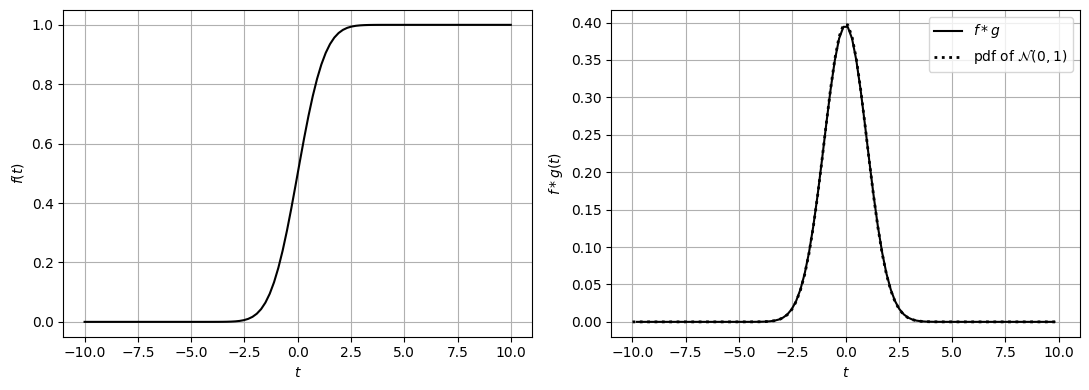

max |f*g - pdf| = 0.0027


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

t = np.linspace(-10, 10, 100)
dt = t[1] - t[0]
f = norm.cdf(t)
g = np.array([1, 0, -1]) / (2 * dt)
phi = np.convolve(f, g, mode='same')[1:-1]      # drop the two boundary points

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(t, f, 'k', linewidth=1.5)
axs[0].set_ylabel('$f(t)$')
axs[1].plot(t[1:-1], phi, 'k', linewidth=1.5, label='$f*g$')
axs[1].plot(t, norm.pdf(t), 'k:', linewidth=2, label=r'pdf of $\mathcal{N}(0,1)$')
axs[1].set_ylabel('$f*g(t)$')
axs[1].legend()
for ax in axs:
    ax.set_xlabel('$t$')
    ax.grid(True)
plt.tight_layout()
plt.show()
print(f"max |f*g - pdf| = {np.max(np.abs(phi - norm.pdf(t[1:-1]))):.4f}")